# Análise de Séries Temporais.
### Produção de Automóveis no Brasil entre 1957- 2023

- Os dados foram importados do ipeadata através do [site](http://www.ipeadata.gov.br/)

- Trata a quantidade em número automóveis produzidos mensalmente no Brasil.
#### DESCRIÇÂO.
- **Frequência:** Mensal de 1957.01 até 2023.02
- **Fonte:** Associação Nacional dos Fabricantes de Veículos Automotores, Anuário Estatístico da Indústria Automobilística Brasileira ou Carta Mensal (Anfavea)
- **Unidade:** Unidade
- **Comentário:** Quadro: Licenciamento - autoveículos. Obs.: Engloba automóveis, veículos comerciais leves (caminhonetes de uso misto, utilitários e caminhonetes de carga) e veículos comerciais pesados (caminhões e ônibus). 


## Tratamento os dados

- importando pacotes iniciais.

In [1]:
import pandas as pd
import numpy as np
import ipeadatapy as ipeadata
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)


### importando os dados


- importando a biblioteca ipeadata para escolher os dados.

In [ ]:
all_series = ipeadata.list_series()
#all_series.to_excel("all_series.xlsx")# salvando como excel para avaliar melhor. 
all_series


In [3]:
st_mensal=ipeadata.metadata( frequency = 'Mensal', country = 'BRA')
#st_mensal.to_excel("st_mensal.xlsx")
st_mensal.head()

              

,CODE,NAME,COMMENT,LAST UPDATE,BIG THEME,SOURCE ACRONYM,SOURCE,SOURCE URL,FREQUENCY,MEASURE,UNIT,SERIES STATUS,THEME CODE,COUNTRY,NUMERICA
6,ABATE12_ABPEAV12,Abate - aves - peso das carcaças,Fonte: Para 1975 - 1996: Pesquisa Mensal de Ab...,2009-07-29T14:54:55-03:00,Macroeconômico,IBGE/Coagro,Instituto Brasileiro de Geografia e Estatístic...,www.ibge.gov.br,Mensal,Tonelada,mil,I,1,BRA,True
7,ABATE12_ABPEBO12,Abate - bois - peso das carcaças,O abate de animais é mensurado por sua quantid...,2023-03-15T09:08:01.163-03:00,Macroeconômico,IBGE/Coagro,Instituto Brasileiro de Geografia e Estatístic...,www.ibge.gov.br,Mensal,Tonelada,mil,A,1,BRA,True
8,ABATE12_ABPEBV12,Abate - bovinos - peso das carcaças,O abate de animais é mensurado por sua quantid...,2023-03-15T09:08:01.163-03:00,Macroeconômico,IBGE/Coagro,Instituto Brasileiro de Geografia e Estatístic...,www.ibge.gov.br,Mensal,Tonelada,mil,A,1,BRA,True
9,ABATE12_ABPEFR12,Abate - frangos - peso das carcaças,O abate de animais é mensurado por sua quantid...,2023-03-15T09:08:01.163-03:00,Macroeconômico,IBGE/Coagro,Instituto Brasileiro de Geografia e Estatístic...,www.ibge.gov.br,Mensal,Tonelada,mil,A,1,BRA,True
10,ABATE12_ABPENO12,Abate - novilhos - peso das carcaças,O abate de animais é mensurado por sua quantid...,2023-03-15T09:08:01.163-03:00,Macroeconômico,IBGE/Coagro,Instituto Brasileiro de Geografia e Estatístic...,www.ibge.gov.br,Mensal,Tonelada,mil,A,1,BRA,True


- escolhendo e conhecendo os dados 

In [2]:
ipeadata.describe('ANFAVE12_QPASSAM12')

,Produção - automóveis - montados - qde.
Name,Produção - automóveis - montados - qde.
Code,ANFAVE12_QPASSAM12
Big Theme,Macroeconômico
Theme,Produção
Source,Associação Nacional dos Fabricantes de Veículo...
Source acronym,Anfavea
Comment,Quadro: Produção - autoveículos. Obs.: Refere...
Last update,2023-03-16T16:24:01.51-03:00
Frequency,Mensal
Measure,Unidade


- Conhecendo nosso banco de dados.

In [3]:
df=ipeadata.timeseries('ANFAVE12_QPASSAM12')
df.sort_values(by=['DATE'] ,ascending=False).head(24)

,YEAR,DAY,MONTH,CODE,RAW DATE,VALUE (Unidade)
DATE,,,,,,
2023-02-01,2023,1,2,ANFAVE12_QPASSAM12,2023-02-01T00:00:00-03:00,123482.0
2023-01-01,2023,1,1,ANFAVE12_QPASSAM12,2023-01-01T00:00:00-03:00,125060.0
2022-12-01,2022,1,12,ANFAVE12_QPASSAM12,2022-12-01T00:00:00-03:00,149478.0
2022-11-01,2022,1,11,ANFAVE12_QPASSAM12,2022-11-01T00:00:00-03:00,168136.0
2022-10-01,2022,1,10,ANFAVE12_QPASSAM12,2022-10-01T00:00:00-03:00,164674.0
2022-09-01,2022,1,9,ANFAVE12_QPASSAM12,2022-09-01T00:00:00-03:00,156727.0
2022-08-01,2022,1,8,ANFAVE12_QPASSAM12,2022-08-01T00:00:00-03:00,181017.0
2022-07-01,2022,1,7,ANFAVE12_QPASSAM12,2022-07-01T00:00:00-03:00,160169.0
2022-06-01,2022,1,6,ANFAVE12_QPASSAM12,2022-06-01T00:00:00-03:00,158384.0


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 794 entries, 1957-01-01 to 2023-02-01
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YEAR             794 non-null    int64  
 1   DAY              794 non-null    int64  
 2   MONTH            794 non-null    int64  
 3   CODE             794 non-null    object 
 4   RAW DATE         794 non-null    object 
 5   VALUE (Unidade)  794 non-null    float64
dtypes: float64(1), int64(3), object(2)
memory usage: 43.4+ KB


In [27]:
df.columns

Index(['YEAR', 'DAY', 'MONTH', 'CODE', 'RAW DATE', 'VALUE (Unidade)'], dtype='object')


# Análise Da Série.

- Vamos começar com uma breve análise descritiva a respeito da nossa variavel de estudo o número de cabeças abatidas(VALUE(Cabeça)). **lembrando** a unidade de valor são  mil cabeças.


In [6]:
round(df['VALUE (Unidade)'].describe(),2)


count       794.00
mean      92017.81
std       71969.08
min         497.00
25%       39573.75
50%       67205.00
75%      147764.25
max      278924.00
Name: VALUE (Unidade), dtype: float64

- podemos notar que a média de abate por toda a série é de 1660, com uma variância de 729 que é alta em comparação com a média, um mínimo de 324 abates e um maximo de 3043 abates.


#### Agora conhecendo a série

<AxesSubplot:xlabel='DATE'>

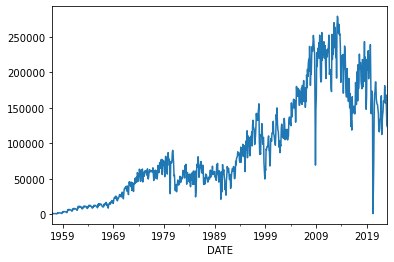

In [5]:
df['VALUE (Unidade)'].plot()

In [8]:
# periodo da série 
print(df.index.min(),
df.index.max())

1957-01-01 00:00:00 2023-02-01 00:00:00


Timestamp('1957-01-01 00:00:00')

### A Respeito da série.
- Por meio do gráfico é possível notar o comportamento da série, podemos ver que exite uma **tendencia** crescente apesar de uma grave queda proximo a 2019 mas já vinha em decaimento apartir do pico em 2010, a série também possui **sazonalidade**.  

- Pode ser notado que a série tem um comportamento e próximo de 2009 e o comportamento muda , isso nos indica uma possível falta de estacionariedade. 


In [7]:
# elimina os warnings das bibliotecas
import warnings
warnings.filterwarnings("ignore")

In [8]:
from pandas.plotting import autocorrelation_plot
from matplotlib import pyplot as plt

- instalando alguns pacotes para plotagens e os gráficos de correlação fac e facp. 

In [9]:
import pandas.util.testing as tm
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf
from matplotlib import pyplot

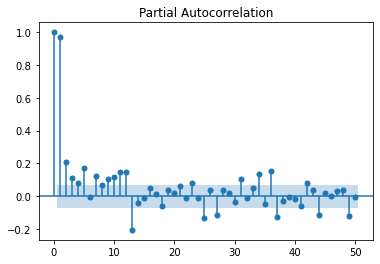

In [9]:
plot_pacf(df['VALUE (Unidade)'], lags=50)
pyplot.show()

- Separando os componentes da série , podemos observar sua tendência crescente apartir dos anos 90, sua sazonalidade separadamente e conseguimos ver os residuais.

A série é sazonal, seu valor de auto correlação é : 0.9713518927405802


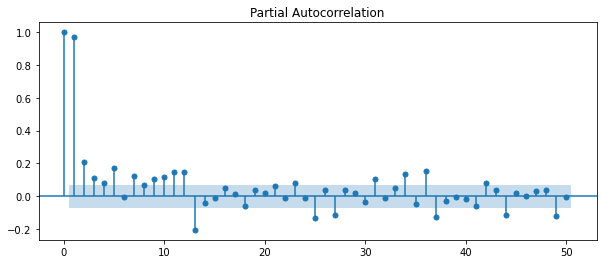

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

# Carregue sua série como um DataFrame do pandas
#df = pd.read_csv('seu_arquivo.csv', index_col='data', parse_dates=['data'])

# Calcule a autocorrelação
autocorr = pd.Series(df['VALUE (Unidade)']).autocorr()

# Plotar a autocorrelação
fig, ax = plt.subplots(figsize=(10, 4))
plot_pacf(df['VALUE (Unidade)'], lags=50,ax=ax)

# Verificar se há um padrão significativo na autocorrelação
if abs(autocorr) > 0.5:
    print("A série é sazonal, seu valor de auto correlação é :",autocorr)
else:
    print("A série não é sazonal")

plt.show()


- Com base na análise visual da série temporal, é possível perceber que a amplitude das oscilações da série aumenta com o tempo, o que sugere que uma decomposição multiplicativa pode ser mais apropriada para essa série. Além disso, o fato da amplitude das oscilações aumentar com o tempo indica que a série pode ter uma componente sazonal com variação proporcional à média, o que reforça a escolha da decomposição multiplicativa.



In [10]:
from statsmodels.tsa.seasonal import seasonal_decompose
resultados = seasonal_decompose(df['VALUE (Unidade)'], model='multiplicative', period=12)
saida1 = resultados.resid

In [46]:
resultados2 = seasonal_decompose(df['VALUE (Unidade)'], model='aditive', period=12)
saida2 = resultados2.resid

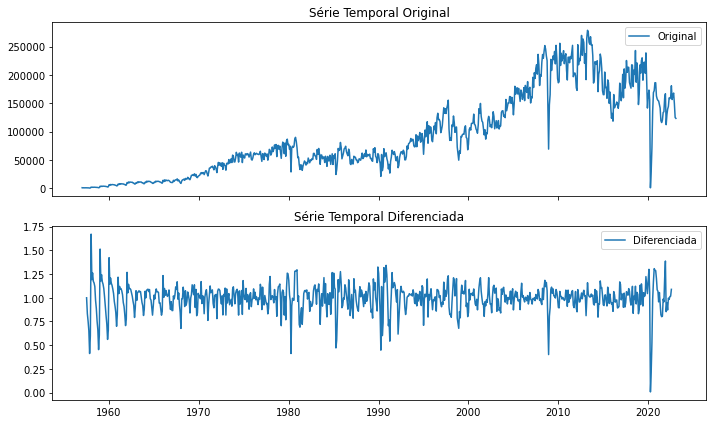

In [21]:

resultados = seasonal_decompose(df['VALUE (Unidade)'], model='multiplicative', period=12)
saida1 = resultados.resid

# plotar a série temporal original e a diferenciada
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax[0].plot(df.index, df['VALUE (Unidade)'], label='Original')
ax[0].set_title('Série Temporal Original')
ax[0].legend()

ax[1].plot(df.index, saida1, label='Diferenciada')
ax[1].set_title('Série Temporal Diferenciada')
ax[1].legend()

plt.tight_layout()
plt.show()

plt.show()


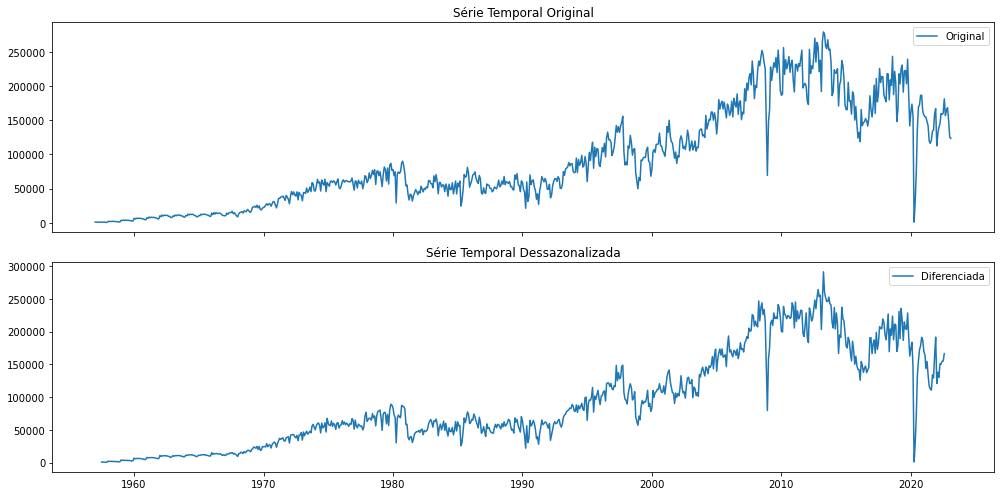

In [43]:
saida2 = resultados.trend*resultados.resid

# plotar a série temporal original e a diferenciada
fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

ax[0].plot(df.index, df['VALUE (Unidade)'], label='Original')
ax[0].set_title('Série Temporal Original')
ax[0].legend()

ax[1].plot(df.index, saida2, label='Diferenciada')
ax[1].set_title('Série Temporal Dessazonalizada')
ax[1].legend()

plt.tight_layout()
plt.show()

plt.show()

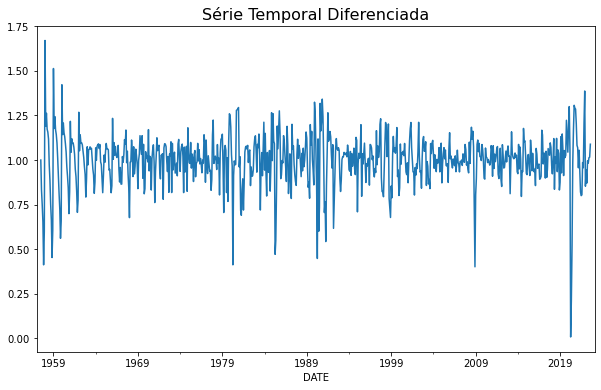

In [11]:
fig = plt.figure(figsize=(10,6))
saida1.plot()
plt.title('Série Temporal Diferenciada', size=16)
plt.show()

- comparando o residual da série com a sua sazonalidade.

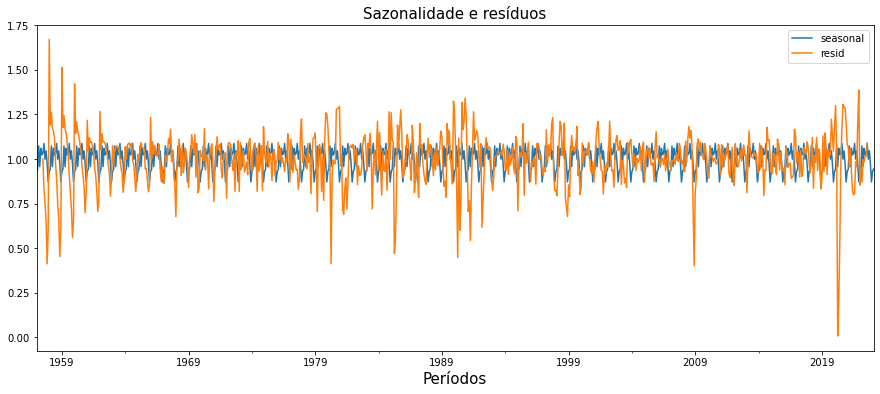

In [12]:
plt.figure(figsize=(15,6))
resultados.seasonal.plot(legend=True)
resultados.resid.plot(legend=True)
plt.xlabel('Períodos',size=15)
plt.title('Sazonalidade e resíduos',size=15);

- Examinando apenas a tendência, obsrvando melhor o comportamento crescente notado apartir de 1999.

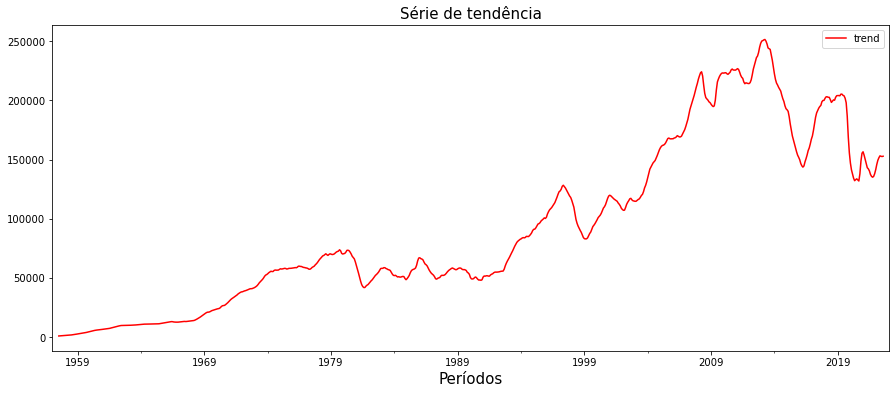

In [34]:
plt.figure(figsize=(15,6))
resultados.trend.plot(legend=True, color='r')
plt.xlabel('Períodos',size=15)
plt.title('Série de tendência',size=15);

- Multiplicando a tendência pela sazonalidade obtemos a forma da série dessazonalizada.

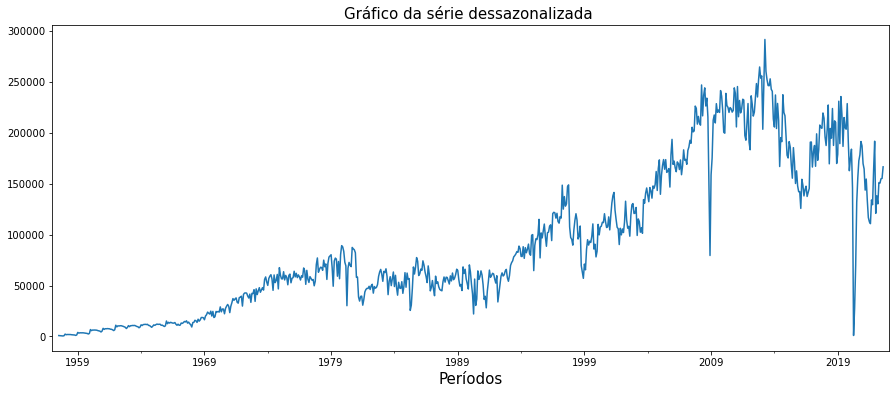

In [36]:
df3 = (resultados.trend*resultados.resid)
plt.figure(figsize=(15,6))
df3.plot()
plt.xlabel('Períodos',size=15)
plt.title('Gráfico da série dessazonalizada ',size=15);

- Comparando a série original com a sazonalidade da série.

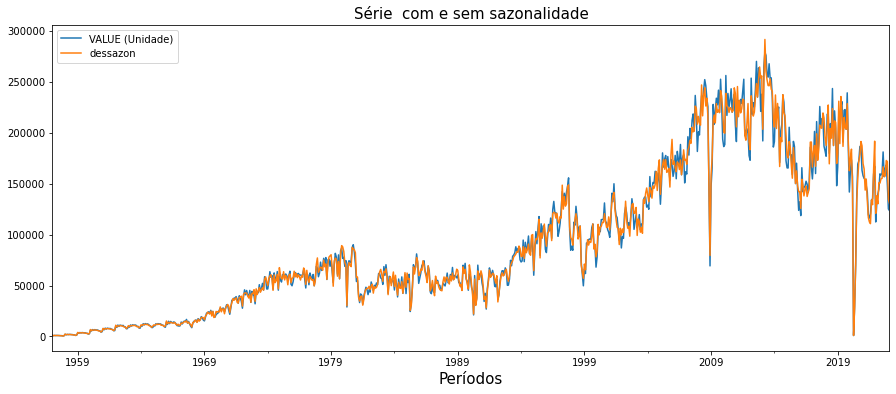

In [14]:
from datetime import datetime
df['sazonalidade']=pd.DataFrame(data=resultados.seasonal.values, index=pd.date_range(start=datetime(1957 , 1,1), 
                                                              end = datetime(2023,2,1), freq='MS'))
df['dessazon']=df['VALUE (Unidade)']/df['sazonalidade']

#gráfico das séries original e dessazonalizada
df[['VALUE (Unidade)','dessazon']].plot(figsize=(15,6))
plt.xlabel('Períodos',size=15)
plt.title('Série  com e sem sazonalidade',size=15);

# Estacionariedade.
- Observando o teste de decomposição ADF(Augmented Dickey-Fuller) podemos notar a falta de estacionariedade,pois o teste ADF aceitou a presença de raiz unitária, logo não se trata de uma série e sim de um passeio aleatório.

- Agora vamos olhar os graficos de autocorrelação.


In [19]:
from statsmodels.tsa.stattools import adfuller

In [44]:
from statsmodels.tsa.stattools import adfuller
resultado1=adfuller(df['VALUE (Unidade)'].dropna())
resultado1
print(f'Teste ADF: {resultado1[0]}')
print(f'p-valor: {resultado1[1]}')
print(f'Defasagens usadas no teste: {resultado1[2]}')
print(f'Observações usadas: {resultado1[3]}')
print(f'Valores críticos: {resultado1[4]}')


Teste ADF: -1.3170772556737846
p-valor: 0.6213236865641034
Defasagens usadas no teste: 12
Observações usadas: 781
Valores críticos: {'1%': -3.438750669890019, '5%': -2.8652477937238703, '10%': -2.56874438754281}


- o gráfico de auto correlção de toda a série mostra um decaimento lento, com vários lags.

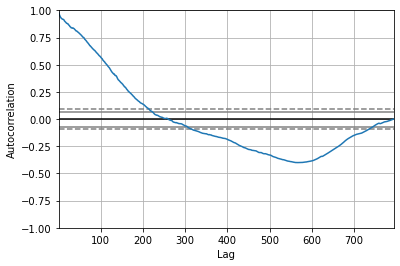

In [29]:
autocorrelation_plot(df['dessazon'])
pyplot.show()

- Observando a FAC até o lag 175 vemos com o decaimento é lento, vai ser nescessário uma diferenciação através das médias moveis.

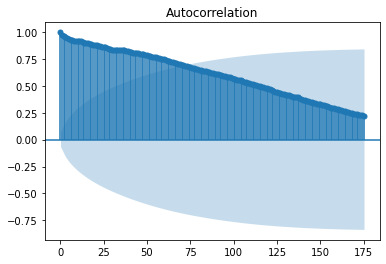

In [28]:
plot_acf(df['dessazon'], lags=175)
pyplot.show()

- Ao realizarmos uma diferenciação podemos notar que o Teste ADF rejeitou a hipótese nula logo a série passa a ser estácionária.

<AxesSubplot:xlabel='DATE'>

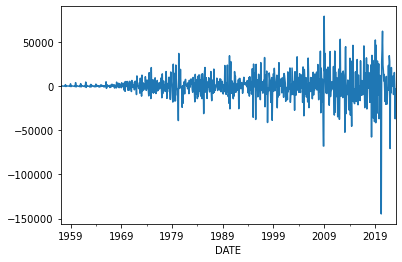

In [35]:
from statsmodels.tsa.statespace.tools import diff
df_dessazon_diff=diff(df['dessazon'],k_diff=1)
df_dessazon_diff.plot()

In [22]:
resultado1=adfuller(df_dessazon_diff.dropna())
resultado1
print(f'Teste ADF: {resultado1[0]}')
print(f'p-valor: {resultado1[1]}')
print(f'Defasagens usadas no teste: {resultado1[2]}')
print(f'Observações usadas: {resultado1[3]}')
print(f'Valores críticos: {resultado1[4]}')

Teste ADF: -9.756542635237668
p-valor: 7.762344483078438e-17
Defasagens usadas no teste: 13
Observações usadas: 779
Valores críticos: {'1%': -3.4387723094153286, '5%': -2.8652573313919625, '10%': -2.5687494684274794}


In [62]:
resultado1=adfuller(df_dessazon_diff.dropna())
resultado1
print(f'Teste ADF: {resultado1[0]}')
print(f'p-valor: {resultado1[1]}')
print(f'Defasagens usadas no teste: {resultado1[2]}')
print(f'Observações usadas: {resultado1[3]}')
print(f'Valores críticos: {resultado1[4]}')

Teste ADF: -11.091712450250675
p-valor: 4.066629895414483e-20
Defasagens usadas no teste: 11
Observações usadas: 781
Valores críticos: {'1%': -3.438750669890019, '5%': -2.8652477937238703, '10%': -2.56874438754281}


### Avaliando a autocorrelação (FAC) e (FACP)

- Plotando o gráfico ACF da série diferenciada vemos que as defasagens mais significativas é no lag 1.

- Logo as possíveis ordens de q podem ser 0 e 1

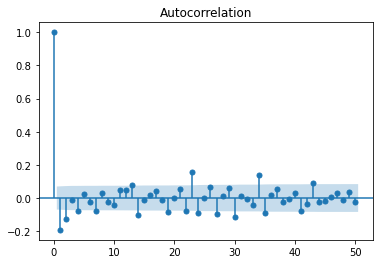

In [30]:
import pandas.util.testing as tm
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf
from matplotlib import pyplot
plot_acf(df_dessazon_diff,lags=50);

- Plotando o gráfico PACF da série diferenciada vemos que as defasagens mais significativas é no lag 1 

- Logo as possíveis ordens de q podem ser 0 e 1

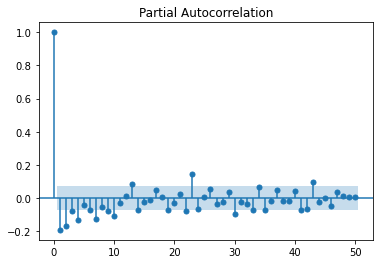

In [31]:
from matplotlib import pyplot
plot_pacf(df_dessazon_diff,lags=50);

### Testando o melhor modelo arima(auto arima)  pelo método stepwise.
- Ainda não se trata do modelo final e sim da composição dos elementos (p,d,q), dado uma dimensão para os parametros p,q,d com base no observado nos plots de FAC e FACP.

- Importando pacotes para o auto-arima e para o summary do modelo arima.

In [25]:
from pmdarima import auto_arima
from statsmodels.tsa.arima.model import ARIMA
from matplotlib import pyplot

In [57]:
df['sazonalidade2']=pd.DataFrame(data=resultados2.seasonal.values, index=pd.date_range(start=datetime(1957 , 1,1), 
                                                              end = datetime(2023,2,1), freq='MS'))
df['dessazon2']=df['VALUE (Unidade)']-df['sazonalidade2']
df_dessazon_diff2=diff(df['dessazon2'],k_diff=1)

In [59]:

fit_arima=auto_arima(df['dessazon2'],d=1,start_p=0,start_q=0,max_p=1,max_q=1,
                            seasonal=False,
                            m=12,
                            D=1,
                            start_P=0,
                            start_Q=0,
                            max_P=1,
                            max_Q=1,
                            information_criterion='aic',
                            trace=True,
                            error_action='ignore',
                            stepwise=True)

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=17569.373, Time=0.04 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=17539.339, Time=0.08 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=17526.768, Time=0.06 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=17567.447, Time=0.02 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=17484.944, Time=0.13 sec
 ARIMA(1,1,1)(0,0,0)[0]             : AIC=17479.114, Time=0.14 sec
 ARIMA(0,1,1)(0,0,0)[0]             : AIC=17524.913, Time=0.03 sec
 ARIMA(1,1,0)(0,0,0)[0]             : AIC=17537.453, Time=0.03 sec

Best model:  ARIMA(1,1,1)(0,0,0)[0]          
Total fit time: 0.527 seconds


<AxesSubplot:xlabel='DATE'>

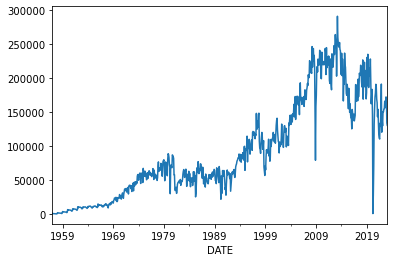

In [64]:
df['dessazon'].plot()

<AxesSubplot:xlabel='DATE'>

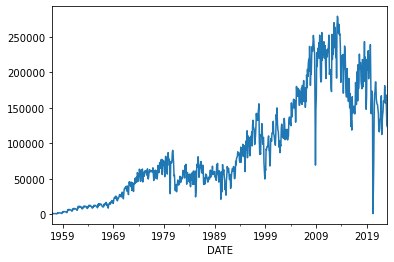

In [65]:
df['VALUE (Unidade)'].plot()

In [60]:
fit_arima=auto_arima(df['dessazon'],d=1,start_p=0,start_q=0,max_p=2,max_q=2,
                            seasonal=False,
                            m=12,
                            D=1,
                            start_P=0,
                            start_Q=0,
                            max_P=2,
                            max_Q=2,
                            information_criterion='aic',
                            trace=True,
                            error_action='ignore',
                            stepwise=True)

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=17528.309, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=17500.400, Time=0.05 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=17485.329, Time=0.04 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=17526.401, Time=0.03 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=17445.175, Time=0.17 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=17446.548, Time=0.24 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=17447.485, Time=0.22 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=17457.417, Time=0.09 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=17479.155, Time=0.05 sec
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=17439.667, Time=0.31 sec
 ARIMA(2,1,2)(0,0,0)[0]             : AIC=17437.319, Time=0.26 sec
 ARIMA(1,1,2)(0,0,0)[0]             : AIC=17440.625, Time=0.23 sec
 ARIMA(2,1,1)(0,0,0)[0]             : AIC=17440.940, Time=0.19 sec
 ARIMA(1,1,1)(0,0,0)[0]             : AIC=17439.058, Time=0.12 sec

Best model:  ARIMA

In [66]:
fit_arima=auto_arima(df['dessazon'],d=1,start_p=0,start_q=0,max_p=2,max_q=2,
                            seasonal=True,
                            m=12,
                            D=1,
                            start_P=0,
                            start_Q=0,
                            max_P=2,
                            max_Q=2,
                            information_criterion='aic',
                            trace=True,
                            error_action='ignore',
                            stepwise=True)

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=17770.576, Time=0.05 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=17571.614, Time=0.30 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=inf, Time=0.99 sec
 ARIMA(1,1,0)(0,1,0)[12]             : AIC=17712.620, Time=0.05 sec
 ARIMA(1,1,0)(2,1,0)[12]             : AIC=17482.093, Time=0.83 sec
 ARIMA(1,1,0)(2,1,1)[12]             : AIC=inf, Time=1.54 sec
 ARIMA(1,1,0)(1,1,1)[12]             : AIC=inf, Time=0.57 sec
 ARIMA(0,1,0)(2,1,0)[12]             : AIC=17474.637, Time=0.60 sec
 ARIMA(0,1,0)(1,1,0)[12]             : AIC=17608.115, Time=0.12 sec
 ARIMA(0,1,0)(2,1,1)[12]             : AIC=inf, Time=1.10 sec
 ARIMA(0,1,0)(1,1,1)[12]             : AIC=inf, Time=0.44 sec
 ARIMA(0,1,1)(2,1,0)[12]             : AIC=17461.726, Time=0.82 sec
 ARIMA(0,1,1)(1,1,0)[12]             : AIC=17550.758, Time=0.25 sec
 ARIMA(0,1,1)(2,1,1)[12]             : AIC=inf, Time=1.28 sec
 ARIMA(0,1,1)(1,1,1)[12]             : AI

- df['dessazon']: É a série temporal a ser modelada.

- d=1: O parâmetro d especifica o número de diferenciações não sazonais a serem aplicadas à série temporal antes de modelá-la. O valor padrão é 1.

- start_p=0: O parâmetro start_p especifica o menor valor possível de p (ordem do termo AR) a ser considerado durante a busca do modelo. O valor padrão é 0.

- start_q=0: O parâmetro start_q especifica o menor valor possível de q (ordem do termo MA) a ser considerado durante a busca do modelo. O valor padrão é 0.

- max_p=2: O parâmetro max_p especifica o maior valor possível de p (ordem do termo AR) a ser considerado durante a busca do modelo. O valor padrão é 2.

- max_q=2: O parâmetro max_q especifica o maior valor possível de q (ordem do termo MA) a ser considerado durante a busca do modelo. O valor padrão é 2.

- seasonal=True: O parâmetro seasonal especifica se o modelo deve ser sazonal ou não. O valor padrão é True.

- m=12: O parâmetro m especifica o número de períodos na temporada. O valor padrão é 12.

- D=1: O parâmetro D especifica o número de diferenciações sazonais a serem aplicadas à série temporal antes de modelá-la. O valor padrão é 1.

- start_P=0: O parâmetro start_P especifica o menor valor possível de P (ordem do termo AR sazonal) a ser considerado durante a busca do modelo. O valor padrão é 0.

- start_Q=0: O parâmetro start_Q especifica o menor valor possível de Q (ordem do termo MA sazonal) a ser considerado durante a busca do modelo. O valor padrão é 0.

- max_P=2: O parâmetro max_P especifica o maior valor possível de P (ordem do termo AR sazonal) a ser considerado durante a busca do modelo. O valor padrão é 2.

- max_Q=2: O parâmetro max_Q especifica o maior valor possível de Q (ordem do termo MA sazonal) a ser considerado durante a busca do modelo. O valor padrão é 2.

- information_criterion='aic': O parâmetro information_criterion especifica o critério de informação a ser usado para selecionar o melhor modelo. Os valores possíveis são 'aic' (Akaike Information Criterion), 'bic' (Bayesian Information Criterion) e 'hqic' (Hannan-

- o modelo trouce o ARIMA(1,1,2) e no caso o SARIMA(1,1,2)(2,1,0)12 com o menor AIC sendo de 'AIC=17437.379'

- a diferenciação de forma adivitva tem um modelo pior que a aditiva pela saida dos seus resíduos. **para comapraão**

In [61]:
model2 = ARIMA(df['dessazon2'], order=(1,1,0))
model_fit2 = model2.fit()
# summary 
print(model_fit2.summary())

                               SARIMAX Results                                
Dep. Variable:              dessazon2   No. Observations:                  794
Model:                 ARIMA(1, 1, 0)   Log Likelihood               -8766.727
Date:                Tue, 18 Apr 2023   AIC                          17537.453
Time:                        13:42:42   BIC                          17546.805
Sample:                    01-01-1957   HQIC                         17541.047
                         - 02-01-2023                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1988      0.020    -10.153      0.000      -0.237      -0.160
sigma2      2.347e+08      4e-11   5.86e+18      0.000    2.35e+08    2.35e+08
Ljung-Box (L1) (Q):                   0.61   Jarque-

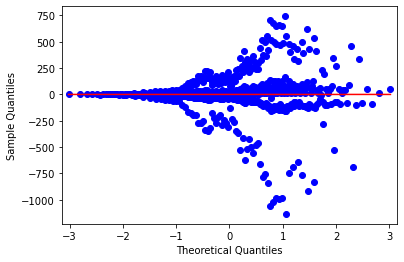

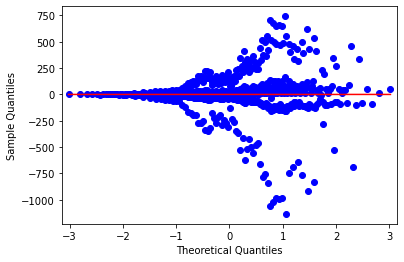

In [53]:
residuals2 = DataFrame(model_fit2.resid)
qqplot(residuals2,line='r')

- Aplicando o ARIMA(1,1,2) , obtemos a seguinte saída:

In [72]:
model = ARIMA(df['dessazon'], order=(1,1,2))
model_fit = model.fit()
# summary 
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:               dessazon   No. Observations:                  794
Model:                 ARIMA(1, 1, 2)   Log Likelihood               -8716.312
Date:                Tue, 18 Apr 2023   AIC                          17440.625
Time:                        14:04:55   BIC                          17459.328
Sample:                    01-01-1957   HQIC                         17447.813
                         - 02-01-2023                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5778      0.068      8.495      0.000       0.444       0.711
ma.L1         -0.8655      0.075    -11.481      0.000      -1.013      -0.718
ma.L2          0.0005      0.049      0.010      0.9

- Removendo uma média móvel 

In [101]:
model = ARIMA(df['dessazon'], order=(1,1,1))
model_fit = model.fit()
# summary 
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:               dessazon   No. Observations:                  794
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -8716.529
Date:                Tue, 18 Apr 2023   AIC                          17439.058
Time:                        15:45:05   BIC                          17453.085
Sample:                    01-01-1957   HQIC                         17444.448
                         - 02-01-2023                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5772      0.028     20.544      0.000       0.522       0.632
ma.L1         -0.8648      0.022    -40.111      0.000      -0.907      -0.823
sigma2       2.17e+08   7.81e-11   2.78e+18      0.0

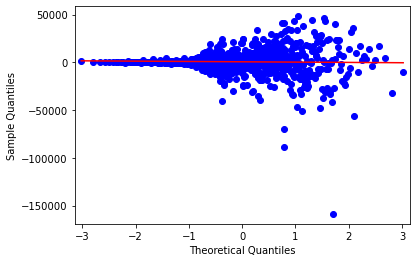

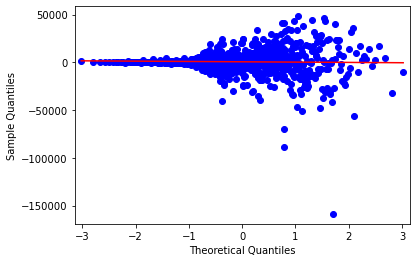

In [102]:
from pandas import DataFrame
residuals = DataFrame(model_fit.resid)
from statsmodels.graphics.gofplots import qqplot
qqplot(residuals,line='r')

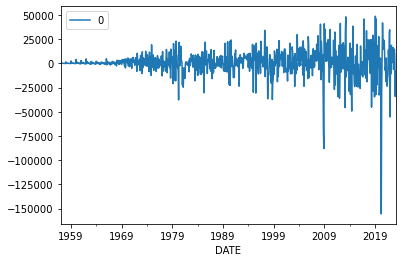

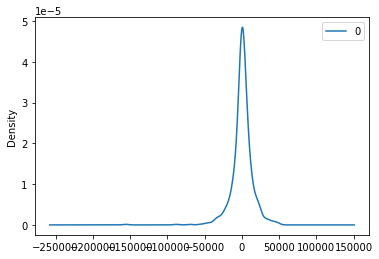

,0
count,794.000000
mean,579.813975
std,14294.246577
min,-155571.854622
25%,-3731.152769
50%,518.624838
75%,6113.811890
max,48680.070165


In [68]:

residuals.plot()
pyplot.show()
#
residuals.plot(kind='kde')
pyplot.show()
#
residuals.describe()



# Previsão Dos Dados


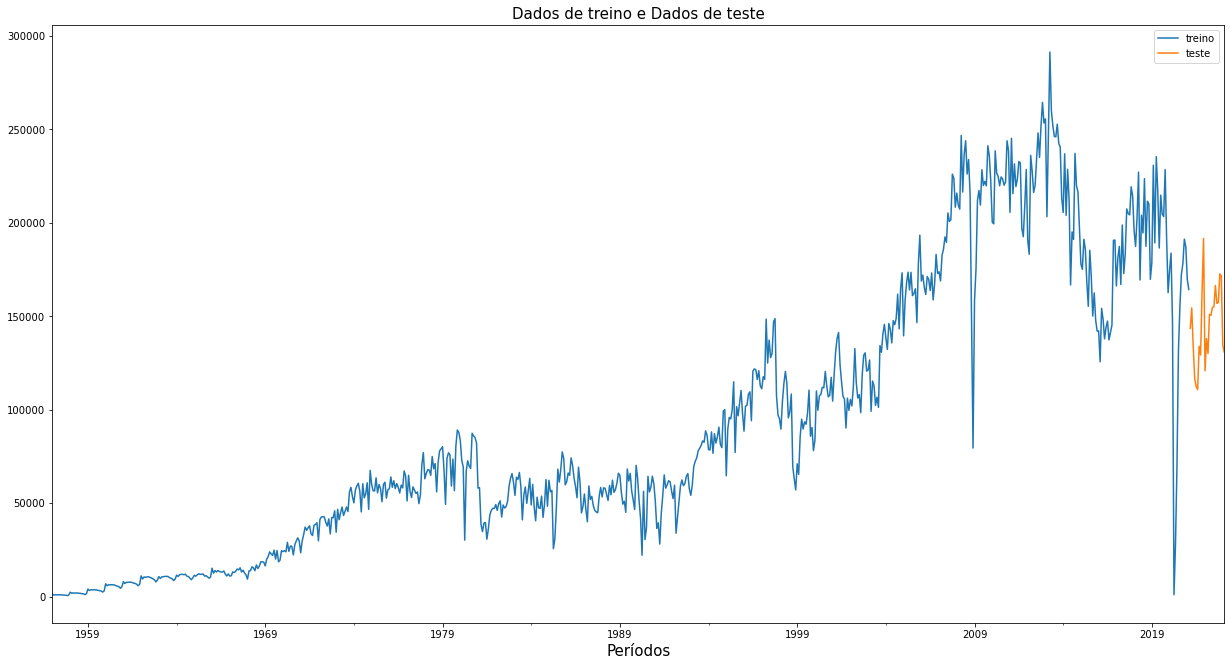

In [103]:


treino = df['dessazon'].iloc[:-24]
teste = df['dessazon'].iloc[-24:]
plt.title('Dados de treino e Dados de teste',size=15)
treino.plot(figsize=(21,11))
teste.plot()
plt.xlabel('Períodos',size=15)
plt.legend(['treino','teste']);

In [104]:
#Vamos gerar um novo modelo para, porém apenas usando os dados de treino
teste1 = ARIMA(treino,order=(1,1,1)).fit()
print(teste1.summary())

                               SARIMAX Results                                
Dep. Variable:               dessazon   No. Observations:                  770
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -8441.011
Date:                Tue, 18 Apr 2023   AIC                          16888.023
Time:                        15:45:16   BIC                          16901.958
Sample:                    01-01-1957   HQIC                         16893.386
                         - 02-01-2021                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5801      0.029     19.991      0.000       0.523       0.637
ma.L1         -0.8620      0.022    -38.923      0.000      -0.905      -0.819
sigma2      2.099e+08   9.74e-11   2.15e+18      0.0

In [105]:
start=len(treino)
end=len(treino) + len(teste) - 1
predicoes1=teste1.predict(start,end,typ='levels').rename('ARIMA(1,1,1)')

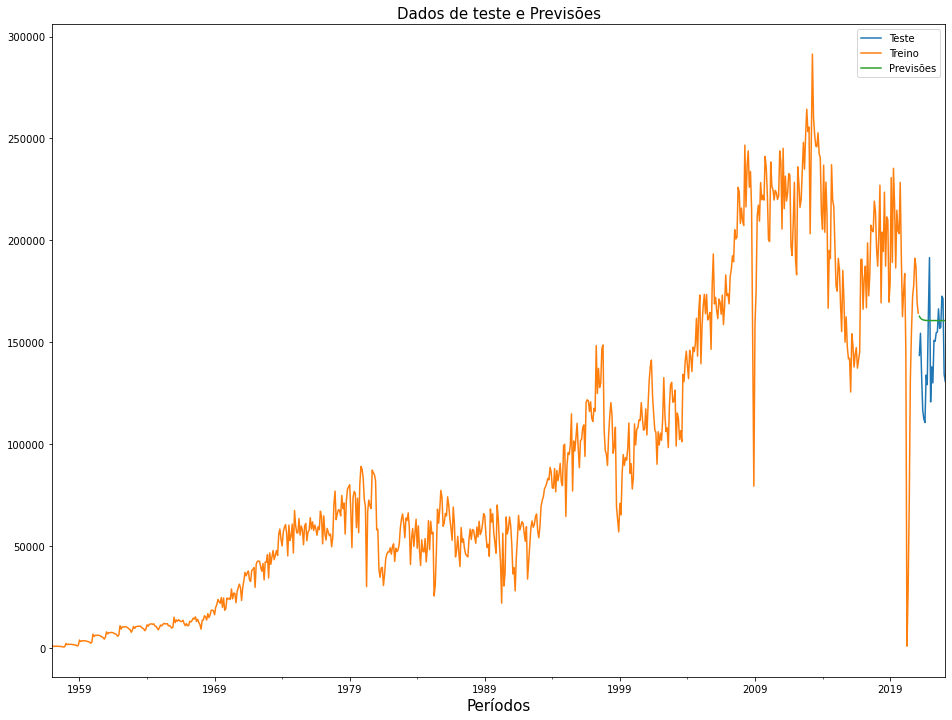

In [106]:
plt.title('Dados de teste e Previsões',size=15)
teste.plot(figsize=(16,12))
treino.plot(figsize=(16,12))
predicoes1.plot(figsize=(16,12))
plt.xlabel('Períodos',size=15)
plt.legend(['Teste','Treino','Previsões']);

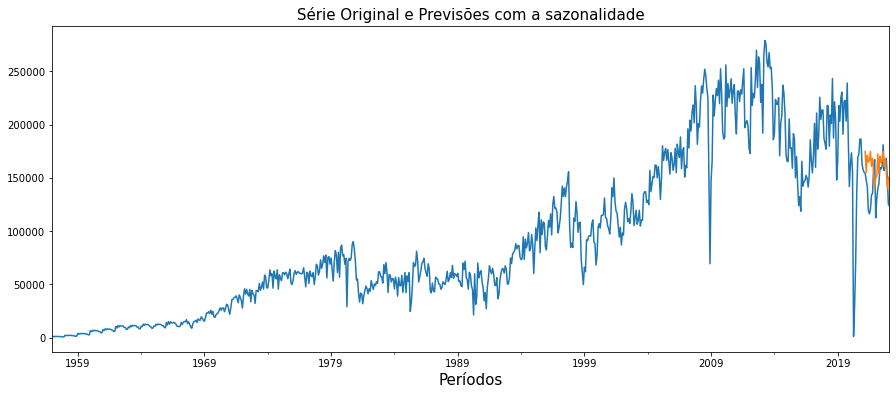

In [111]:
df['previsões 1']=pd.DataFrame(predicoes1,index=teste.index)
#inserindo a sazonalidade multiplicativa
df['prev_sazon']=df['previsões 1']*df['sazonalidade']
#Comparação
df['VALUE (Unidade)'].plot(figsize=(15,6))
df['prev_sazon'].plot()
plt.title('Série Original e Previsões com a sazonalidade',size=15)
plt.xlabel('Períodos',size=15)
plt.show();

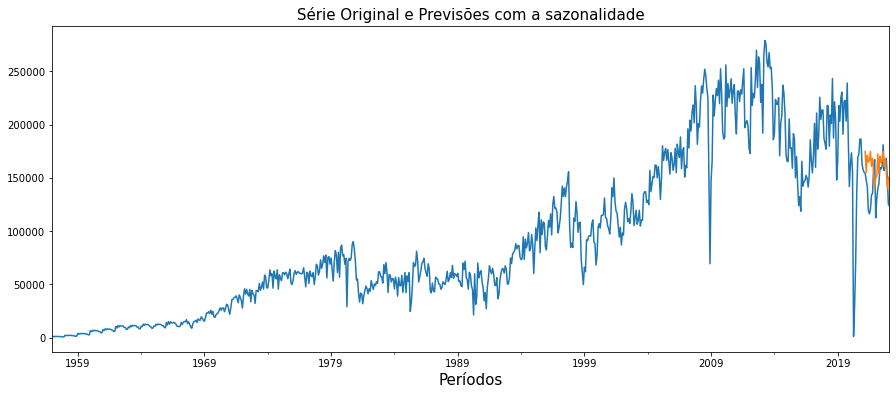

In [79]:
df['previsões 1']=pd.DataFrame(predicoes1,index=teste.index)
#inserindo a sazonalidade multiplicativa
df['prev_sazon']=df['previsões 1']*df['sazonalidade']
#Comparação
df['VALUE (Unidade)'].plot(figsize=(15,6))
df['prev_sazon'].plot()
plt.title('Série Original e Previsões com a sazonalidade',size=15)
plt.xlabel('Períodos',size=15)
plt.show();


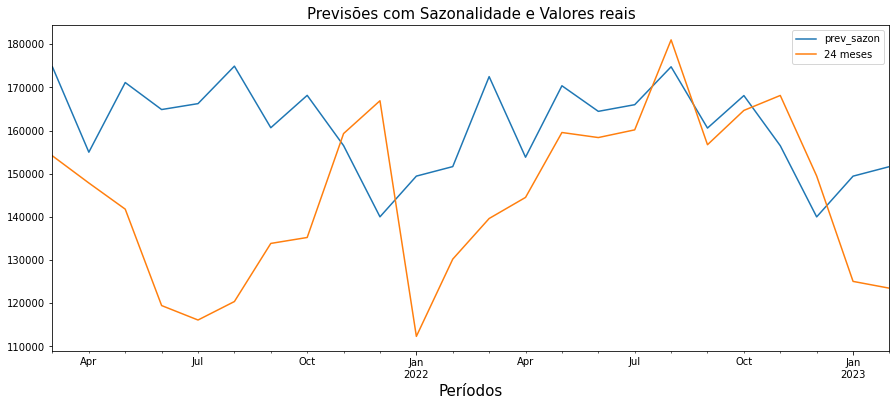

In [114]:
df['24 meses']=df['VALUE (Unidade)'].iloc[-24:]
df1=df[['prev_sazon','24 meses']]
df1= df1.dropna()
df1.plot(figsize=(15,6))
plt.title('Previsões com Sazonalidade e Valores reais',size=15)
plt.xlabel('Períodos',size=15)
plt.show();

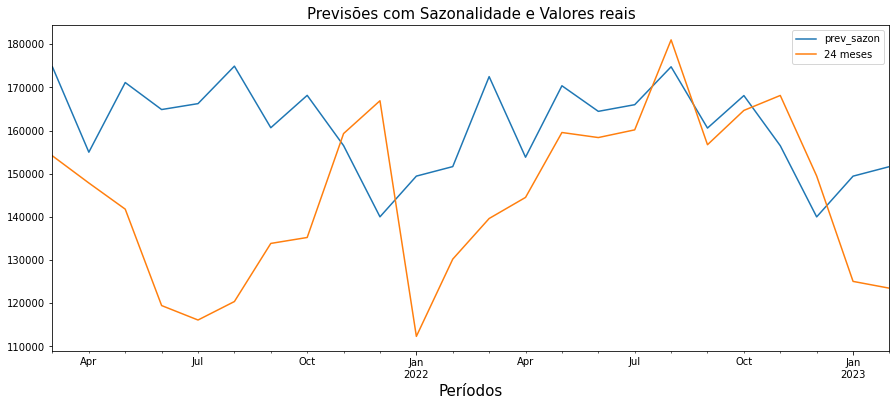

In [80]:
df['24 meses']=df['VALUE (Unidade)'].iloc[-24:]
df1=df[['prev_sazon','24 meses']]
df1= df1.dropna()
df1.plot(figsize=(15,6))
plt.title('Previsões com Sazonalidade e Valores reais',size=15)
plt.xlabel('Períodos',size=15)
plt.show();

### Estatisticas 


In [151]:
print("+---------------------------+------------+")
print("|           Métrica          |   Valor    |")
print("+---------------------------+------------+")
print("| A média das previsões      | {:>10,.0f} |".format(round(df1['prev_sazon'].mean())).replace(',', '.'))
print("| A média dos valores reais  | {:>10,.0f} |".format(round(df['24 meses'].mean())).replace(',', '.'))
print("| A média dos valores originais | {:>7,.0f} |".format(round(df['VALUE (Unidade)'].mean())).replace(',', '.'))
print("| Estatística t-student      | {:>10,.0f} |".format(round(np.absolute(sct.ttest_ind(df1['prev_sazon'],df1['24 meses'])[0]))).replace(',', '.'))
print("| P-valor                    | {:>10,.0f} |".format(round(sct.ttest_ind(df1['prev_sazon'],df1['24 meses'])[1], -3)).replace(',', '.'))
print("| RMSE do modelo ARIMA(1,1,1)| {:>10,.0f} |".format(round(rmse(df1['prev_sazon'].iloc[-24:],df['VALUE (Unidade)'].iloc[-24:]))).replace(',', '.'))
print("| MAE do modelo ARIMA(1,1,1) | {:>10,.0f} |".format(round(mean_absolute_error(df1['prev_sazon'].iloc[-24:],df['VALUE (Unidade)'].iloc[-24:]))).replace(',', '.'))
print("| R² do modelo ARIMA(1,1,1)  | {:>10,.0f} |".format(round(r2_score(df1['prev_sazon'].iloc[-24:],df['VALUE (Unidade)'].iloc[-24:]))).replace(',', '.'))
print("+---------------------------+------------+")


+---------------------------+------------+
|           Métrica          |   Valor    |
+---------------------------+------------+
| A média das previsões      |    160.901 |
| A média dos valores reais  |    144.519 |
| A média dos valores originais |  92.018 |
| Estatística t-student      |          4 |
| P-valor                    |          0 |
| RMSE do modelo ARIMA(1.1.1)|     26.054 |
| MAE do modelo ARIMA(1.1.1) |     21.136 |
| R² do modelo ARIMA(1.1.1)  |         -5 |
+---------------------------+------------+


#### Sobre as Estatísticas 
- A média das previsões: é a média das previsões geradas pelo modelo ARIMA.

- A média dos valores reais: é a média dos valores reais da série temporal (dos dois ultimos anos.

- A média dos valores originais: é a média dos valores de toda a séire temporal

- A estatística t-student do teste em módulo: é uma medida de quão significativo é o valor absoluto do coeficiente da regressão em relação ao erro padrão. Quanto maior o valor, mais significativo é o coeficiente.

- O p-valor: é a probabilidade de que o coeficiente da regressão seja igual a zero. Quanto menor o valor, mais significativo é o coeficiente.

- O RMSE: é o erro quadrático médio das previsões em relação aos valores reais. É uma medida da precisão do modelo.

- O MAE: é a média do valor absoluto dos erros de previsão. É uma medida da magnitude dos erros do modelo.

- O R²: é uma medida de quão bem o modelo se ajusta aos dados. Um valor negativo indica que o modelo é muito ruim em ajustar os dados.

- Em geral, quando se faz previsões com modelos ARIMA, é importante olhar tanto para as métricas de precisão (como RMSE e MAE) quanto para as métricas de ajuste (como R²). O fato de o R² ser negativo sugere que o modelo não está ajustando bem aos dados, o que pode indicar que o modelo não está capturando bem as características da série temporal ou que o modelo não é adequado para os dados em questão.

#### Interpretando 
- A média das previsões (160901.1049) é maior do que a média dos valores reais (144518.7917), o que sugere que o modelo está prevendo valores mais altos do que os valores reais observados.

- A estatística t-student do teste em módulo (3.7046) e o p-valor (0.0006) indicam que o coeficiente da regressão é significativo e diferente de zero, o que sugere que o modelo está capturando alguma relação entre as variáveis.

- O RMSE do modelo (26054.1659) é relativamente alto em relação à média dos valores reais, o que sugere que o modelo tem uma precisão moderada na previsão dos dados.

- O MAE do modelo (21135.5587) é menor do que o RMSE, o que sugere que o modelo está acertando melhor a direção das previsões, mas ainda com uma magnitude razoável de erros.

- O valor negativo do R² (-5.4453) indica que o modelo está apresentando um mau ajuste aos dados. Isso significa que o modelo não está capturando todas as complexidades dos dados, e pode ser necessário buscar outras abordagens para melhorar a qualidade da previsão.

- Em resumo, a previsão gerada pelo modelo ARIMA apresenta um desempenho moderado em relação aos dados, mas ainda há espaço para melhorias na precisão e no ajuste aos dados. É importante continuar avaliando a qualidade da previsão e explorar outras técnicas de modelagem, se necessário.

In [123]:
forecast = model_fit.predict(start = len(df['dessazon']),
                          end=len(df['dessazon'])+11,
                          typ='levels').rename('Previsões ARIMA(1,1,1)')*df['sazonalidade'].iloc[-12:].values

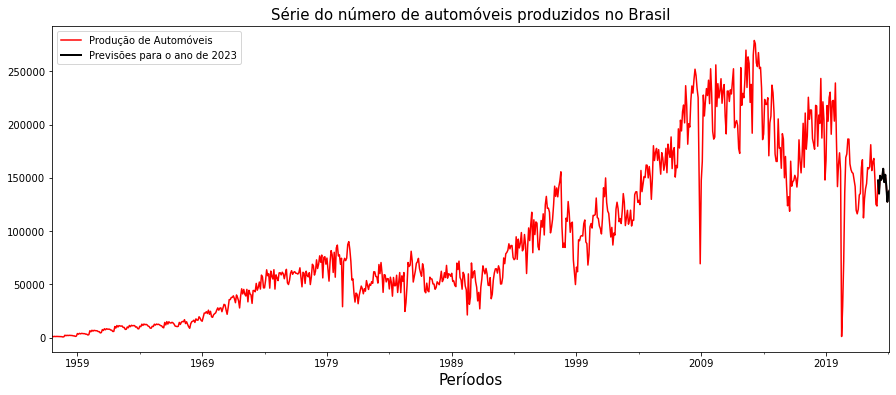

In [133]:
df['VALUE (Unidade)'].append(forecast).plot(figsize=(15,6),color='r')
forecast.plot(color='black',linewidth=2)
plt.xlabel('Períodos',size=15)
plt.title('Série do número de automóveis produzidos no Brasil',size=15)
plt.legend(['Produção de Automóveis','Previsões para o ano de 2023'])
plt.show()

- os dois ultimos anos da previsao e da série original

In [125]:
print(round(df1[['prev_sazon','24 meses']]))

            prev_sazon  24 meses
DATE                            
2021-03-01    174754.0  154138.0
2021-04-01    154995.0  147859.0
2021-05-01    171132.0  141798.0
2021-06-01    164874.0  119461.0
2021-07-01    166244.0  116113.0
2021-08-01    174929.0  120394.0
2021-09-01    160662.0  133857.0
2021-10-01    168160.0  135233.0
2021-11-01    156518.0  159310.0
2021-12-01    140020.0  166913.0
2022-01-01    149452.0  112323.0
2022-02-01    151656.0  130221.0
2022-03-01    172501.0  139632.0
2022-04-01    153830.0  144517.0
2022-05-01    170383.0  159555.0
2022-06-01    164455.0  158384.0
2022-07-01    165998.0  160169.0
2022-08-01    174779.0  181017.0
2022-09-01    160583.0  156727.0
2022-10-01    168111.0  164674.0
2022-11-01    156491.0  168136.0
2022-12-01    140007.0  149478.0
2023-01-01    149443.0  125060.0
2023-02-01    151651.0  123482.0


In [140]:
print("Data",'        ' ,"Produção")
print(round(forecast))


Data          Produção
2023-03-01    147464.0
2023-04-01    135111.0
2023-05-01    151956.0
2023-06-01    147955.0
2023-07-01    150092.0
2023-08-01    158486.0
2023-09-01    145854.0
2023-10-01    152838.0
2023-11-01    142353.0
2023-12-01    127398.0
2024-01-01    136009.0
2024-02-01    138033.0
Freq: MS, Name: Previsões ARIMA(1,1,1), dtype: float64


In [132]:
print('A média estimada é :',round(forecast.mean()))

A média estimada é : 144462


## Conclusão:

- O modelo pode ser melhor ajustado.

- sua predição está um pouco acima da média.

- estamos prevendo uma média de 144.462 veículos produzidos no Brasíl para os próximos 12 meses.
